<div align="center">
  <img src="https://raw.githubusercontent.com/devicons/devicon/master/icons/python/python-original.svg" width="80"/>
</div>

<h1 align="center">Redes Neurais Convolucionais</h1>

<h3 align="center">Notebook 01: uma CNN construída do zero</h3>

<p align="center"><b>PhD. Julles Mitoura</b></p>

<div align="center">
  <img src="https://img.shields.io/badge/Python-3776AB?style=for-the-badge&logo=python&logoColor=white"/>
  <img src="https://img.shields.io/badge/Jupyter-F37626?style=for-the-badge&logo=jupyter&logoColor=white"/>
  <img src="https://img.shields.io/badge/NumPy-013243?style=for-the-badge&logo=numpy&logoColor=white"/>
</div>

---

### Onde este notebook se encaixa na aula

| Notebook | Assunto | Ferramenta |
|---|---|---|
| 00 | Como uma rede aprende: erro, derivada e otimização | NumPy |
| **01 (você está aqui)** | **Uma CNN construída do zero, operação por operação** | **NumPy** |
| 02 | CNN com PyTorch em um dataset criado por nós | PyTorch |
| 03 | CNN em datasets reais (MNIST e CIFAR-10) | PyTorch |

> **Pré-requisito:** o notebook `00_optmi.ipynb`. Aqui usamos os mesmos conceitos vistos lá (perda, derivada, gradiente descendente), agora aplicados a imagens.

In [1]:
# Instalação das dependências
%pip install numpy matplotlib --quiet


[notice] A new release of pip available: 22.3 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## O que vamos fazer neste notebook

No notebook 00, um modelo com dois parâmetros aprendeu a prever temperatura. Agora a entrada não é mais um número, é **uma imagem**. E o modelo não vai mais responder "quantos graus", vai responder **"o que é isto?"**.

Para isso vamos construir uma **CNN** (*Convolutional Neural Network*, ou rede neural convolucional) usando **apenas NumPy**, escrevendo cada operação na mão. Nada de biblioteca pronta ainda: primeiro entender, depois automatizar. No notebook 02 tudo isso vira poucas linhas de PyTorch, e aí você já vai saber o que está acontecendo por baixo.

### Antes de começar: o que é uma imagem para o computador

Uma imagem é uma **tabela de números**. Cada número é um pixel e diz o quanto aquele pontinho é claro ou escuro. Uma figura em preto e branco de 6 por 6 é uma tabela de 6 linhas por 6 colunas, ou seja, 36 números, e nada além disso. Não existe "imagem" para o computador, existe tabela.

### Roteiro

| Seção | Conteúdo |
|---|---|
| **1** | O problema: reconhecer dois desenhos, O e X |
| **2** | Por que uma rede comum não é boa com imagens |
| **3** | A convolução: filtro, mapa de características, ReLU e pooling |
| **4** | Montando a arquitetura da nossa CNN |
| **5** | Forward: da imagem até a resposta |
| **6** | Backward: como a rede corrige os próprios filtros |
| **7** | Treinamento e avaliação |
| **8** | Conclusão |

> **Tempo estimado:** 35 minutos. Execute as células em ordem, de cima para baixo.

## 1. O problema: reconhecer dois desenhos

Queremos que o computador olhe para um desenho de 6 por 6 quadradinhos e diga se ele é um **O** ou um **X**.

Cada desenho é uma tabela de 6 linhas por 6 colunas onde:

- `1` significa quadradinho pintado;
- `0` significa quadradinho vazio.

| Desenho | Como é | Rótulo que usamos |
|---|---|---|
| **O** | um contorno arredondado | 0 |
| **X** | duas diagonais cruzadas | 1 |

O **rótulo** (*label*) é a resposta certa, aquilo que queremos que a rede acerte. Chamar o O de "0" e o X de "1" é apenas uma convenção nossa, porque o computador trabalha com números e não com letras.

Esse tipo de tarefa se chama **classificação**: a resposta não é um valor numérico qualquer (como a temperatura do notebook 00), é uma **categoria** entre opções possíveis.

Execute a célula abaixo para ver os dois desenhos junto com os números que os representam.

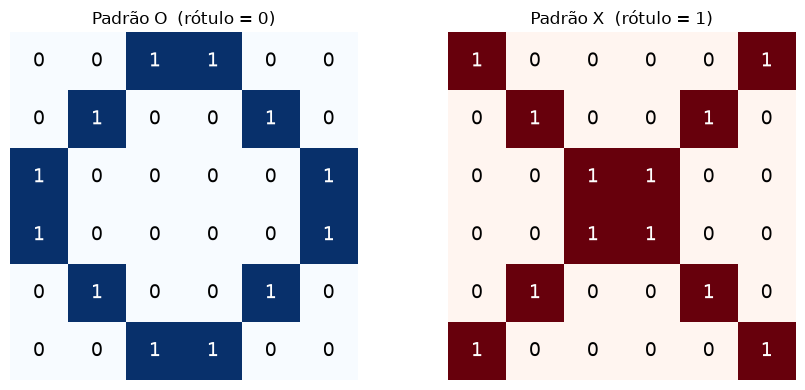

Dimensão de cada entrada: (6, 6)  (36 pixels)


In [2]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# Padrões base 6×6
O_base = np.array([
    [0, 0, 1, 1, 0, 0],
    [0, 1, 0, 0, 1, 0],
    [1, 0, 0, 0, 0, 1],
    [1, 0, 0, 0, 0, 1],
    [0, 1, 0, 0, 1, 0],
    [0, 0, 1, 1, 0, 0]
], dtype=float)

X_base = np.array([
    [1, 0, 0, 0, 0, 1],
    [0, 1, 0, 0, 1, 0],
    [0, 0, 1, 1, 0, 0],
    [0, 0, 1, 1, 0, 0],
    [0, 1, 0, 0, 1, 0],
    [1, 0, 0, 0, 0, 1]
], dtype=float)

# Visualização
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, M, titulo, cmap in [
    (axes[0], O_base, 'Padrão O  (rótulo = 0)', 'Blues'),
    (axes[1], X_base, 'Padrão X  (rótulo = 1)', 'Reds'),
]:
    ax.imshow(M, cmap=cmap, vmin=0, vmax=1)
    for i in range(6):
        for j in range(6):
            ax.text(j, i, int(M[i, j]), ha='center', va='center',
                    fontsize=14, color='white' if M[i, j] > 0.5 else 'black')
    ax.set_title(titulo, fontsize=12)
    ax.axis('off')
plt.tight_layout()
plt.show()

print(f'Dimensão de cada entrada: {O_base.shape}  ({O_base.size} pixels)')


## 2. Por que uma rede comum não funciona bem com imagens

A rede mais simples que existe se chama **rede totalmente conectada** (ou FNN, de *Feedforward Neural Network*, também chamada de camada "densa"). Ela só sabe receber uma **lista** de números, nunca uma tabela. Então, para usá-la numa imagem, é preciso **achatar** a tabela, ou seja, enfileirar todas as linhas uma após a outra:

```
tabela 6×6  ->  achatar (flatten)  ->  lista de 36 números  ->  camada densa  ->  resposta
```

Funciona, mas cria três problemas sérios:

| Problema | O que significa na prática |
|---|---|
| **A quantidade de pesos explode** | Numa imagem de 100×100 são 10 000 pesos para **cada** neurônio. Numa foto de celular, milhões. |
| **A vizinhança é perdida** | Depois de achatar, dois pixels que eram vizinhos ficam distantes na lista. A rede não tem como saber que juntos eles formavam uma borda. |
| **A posição importa demais** | O mesmo desenho deslocado dois pixels para o lado vira uma lista completamente diferente, e a rede precisa aprender tudo de novo. |

A **CNN** resolve os três de uma vez com uma ideia simples: em vez de olhar a imagem toda ao mesmo tempo, ela passa um **filtro pequeno** por cima de cada pedacinho da imagem, procurando sempre o mesmo padrão. O filtro é pequeno (poucos pesos), enxerga vizinhanças (porque olha um quadradinho inteiro de uma vez) e é o mesmo em toda a imagem (então encontra o padrão em qualquer posição).

## 3. A convolução, passo a passo

### De onde vem o nome

O nome vem de uma operação matemática chamada **convolução**, muito usada em processamento de sinais. A ideia é: **deslizar uma coisa pequena por cima de uma coisa grande** e, em cada posição, fazer uma conta.

No caso de imagens: deslizamos um quadradinho de números (o filtro) por cima da tabela de pixels, posição por posição, e anotamos o resultado de cada parada.

> Detalhe para quem for ler artigos depois: o que as redes fazem de fato é uma *correlação cruzada*, que é a convolução sem inverter o filtro. O nome "convolucional" pegou por razões históricas, e na prática não muda nada, porque os pesos são aprendidos de qualquer maneira.

### O filtro (também chamado de kernel)

O filtro é uma tabelinha de números, quase sempre de tamanho 3 por 3. Pense nele como um **molde vazado**: dá resultado alto quando o pedaço da imagem embaixo dele se parece com o que ele procura, e resultado baixo quando não se parece.

Por exemplo, este filtro tem os números 1 numa diagonal:

```
0 0 1
0 1 0
1 0 0
```

Ele vai reagir forte em regiões da imagem que tenham uma risca nessa diagonal, e reagir pouco em regiões vazias ou com riscas em outra direção.

**E quem escolhe os números do filtro?** Ninguém. É justamente isso que faz a CNN ser uma rede neural: os 9 números do filtro são **parâmetros**, exatamente como o peso $a$ do notebook 00. Eles começam com valores aleatórios e vão sendo corrigidos pelo treinamento, ou seja, **a rede aprende sozinha o que vale a pena procurar**. Em problemas reais, os filtros da primeira camada quase sempre terminam aprendendo a detectar bordas e mudanças de cor, sem que ninguém peça isso.

### Passo 1: a conta em cada posição

Em cada parada do filtro, multiplicamos cada número do filtro pelo pixel que está embaixo dele, somamos tudo e acrescentamos um viés $b$:

$$z_{ij} = \sum_{p}\sum_{q} x_{i+p,\,j+q} \cdot w_{pq} + b$$

Traduzindo a fórmula: *multiplique casado, some tudo, acrescente o viés*. É a mesma conta do neurônio do notebook 00 ($a \cdot x + b$), só que agora com 9 pesos em vez de 1.

### Passo 2: o mapa de características (feature map)

Juntando o resultado de todas as paradas do filtro, formamos uma nova tabela chamada **mapa de características** (*feature map*). Ela é um mapa de "onde o filtro encontrou o que procurava".

Essa tabela é um pouco menor que a imagem original, porque o filtro não pode passar da borda:

$$\text{lado da saída} = \text{lado da entrada} - \text{lado do filtro} + 1 = 6 - 3 + 1 = 4$$

Então, de uma imagem 6×6 com um filtro 3×3, sai um mapa 4×4.

### Passo 3: ReLU

$$A = \max(0,\; Z)$$

A **ReLU** é a função de ativação que comentamos no notebook 00, e ela é simples assim: **número negativo virou zero, número positivo passa igual**.

Duas razões para usá-la:

- **interpretação:** valor negativo significa "não achei o padrão aqui", e não precisamos de graus de "não achei". Zero resolve;
- **matemática:** sem uma função desse tipo, empilhar camadas seria inútil, porque uma conta linear em cima de outra continua sendo uma conta linear. A ReLU é a "dobra" que permite aprender padrões complexos.

### Passo 4: max pooling

O **max pooling** divide a tabela em blocos (vamos usar blocos 2×2) e **mantém apenas o maior valor de cada bloco**, descartando o resto. Nosso mapa 4×4 vira 2×2.

Parece desperdício, mas tem três efeitos bons:

- **resume:** se o filtro achou o padrão em algum lugar do bloco, o bloco inteiro registra "achei";
- **reduz o tamanho** dos dados, e portanto a quantidade de contas das camadas seguintes;
- **tolera deslocamento:** o mesmo padrão um pixel para o lado provavelmente cai no mesmo bloco e dá o mesmo resultado.

A célula abaixo faz essa conta na mão: primeiro em uma única posição, depois no mapa inteiro.

In [3]:
# Demo: convolução manual no padrão O

W_demo = np.array([[0, 0, 1],
                   [0, 1, 0],
                   [1, 0, 0]], dtype=float)
b_demo = -2.0

# Janela top-left
janela = O_base[:3, :3]
z = np.sum(janela * W_demo) + b_demo
print('Filtro 3×3:')
print(W_demo)
print(f'\nJanela top-left do padrão O:\n{janela.astype(int)}')
print(f'\nDot product + bias = {np.sum(janela * W_demo):.0f} + ({b_demo}) = {z:.0f}')
print(f'→ z[0,0] do Feature Map = {z:.0f}')

# Feature map completo
Z = np.zeros((4, 4))
for i in range(4):
    for j in range(4):
        Z[i, j] = np.sum(O_base[i:i+3, j:j+3] * W_demo) + b_demo

print('\nFeature Map 4×4 (com bias):')
print(Z.astype(int))


Filtro 3×3:
[[0. 0. 1.]
 [0. 1. 0.]
 [1. 0. 0.]]

Janela top-left do padrão O:
[[0 0 1]
 [0 1 0]
 [1 0 0]]

Dot product + bias = 3 + (-2.0) = 1
→ z[0,0] do Feature Map = 1

Feature Map 4×4 (com bias):
[[ 1 -1 -2 -1]
 [-1 -2 -1 -2]
 [-2 -1 -2 -1]
 [-1 -2 -1  1]]


### Lendo o resultado acima

Na primeira parada, no canto superior esquerdo, os três números 1 do filtro caíram exatamente sobre três quadradinhos pintados do desenho, então a soma deu 3. Com o viés de $-2$, o resultado final ficou $+1$.

Em quase todas as outras posições o resultado deu negativo, porque a coincidência foi menor e o viés puxou o valor para baixo. Depois da ReLU, todos esses negativos virarão zero.

Ou seja, o mapa de características está dizendo: *"encontrei o padrão da diagonal no canto superior esquerdo e no canto inferior direito, e em nenhum outro lugar"*, o que descreve bem dois trechos do contorno do O.

Repare também no papel do viés: ele funciona como um **nível de exigência**. Quanto mais negativo, mais coincidência o filtro precisa encontrar para reagir com um valor positivo.

## 4. A arquitetura da nossa CNN

Uma CNN é uma sequência de operações. A nossa vai ser a menor possível, para conseguirmos acompanhar cada número com os próprios olhos:

| Camada | O que faz | Entra | Sai | Parâmetros |
|---|---|---|---|---|
| **Conv 3×3** | passa um filtro procurando um padrão | 6×6 | 4×4 | 9 pesos + 1 viés |
| **ReLU** | zera os valores negativos | 4×4 | 4×4 | nenhum |
| **MaxPool 2×2** | mantém o maior valor de cada bloco | 4×4 | 2×2 | nenhum |
| **Flatten** | achata a tabela em uma lista | 2×2 | 4 números | nenhum |
| **Densa** | combina os 4 números e dá a resposta | 4 números | 2 números | 8 pesos + 2 vieses |
| | | | **Total** | **20 parâmetros** |

Duas observações importantes:

**Por que existe uma camada densa no final?** A convolução responde "onde estão os padrões". Quem decide "então isto é um O" ou "isto é um X" é a camada densa, que olha todos os padrões encontrados de uma vez. Ela é o mesmo neurônio do notebook 00, agora com 4 entradas e 2 saídas.

**Compare os totais:** uma FNN simples para este mesmo problema (`Flatten(36)` seguido de uma densa de 36 para 2) usaria **74 parâmetros**. Nossa CNN usa **20**, e ainda respeita a vizinhança dos pixels. Em imagens de verdade, essa diferença passa de 99%.

### Traduzindo as operações em código

Cada operação da tabela acima vira uma função pequena, nenhuma com mais de seis linhas.

A última delas, `softmax`, é uma novidade em relação ao notebook 00 e merece explicação. A camada densa devolve dois números soltos, que podem ser qualquer coisa, como `2.7` e `-0.4`. A **softmax** transforma esses dois números em **probabilidades**: valores entre 0 e 1 que somam 1, por exemplo `0.96` e `0.04`. Assim a saída da rede passa a ser legível como *"96% de chance de ser um O"*. Ela consegue isso elevando cada número a uma exponencial, o que elimina os negativos e preserva a ordem, e depois dividindo pela soma de todos.

In [4]:
def conv2d(X, W, b):
    kH, kW = W.shape
    H_out = X.shape[0] - kH + 1
    W_out = X.shape[1] - kW + 1
    Z = np.zeros((H_out, W_out))
    for i in range(H_out):
        for j in range(W_out):
            Z[i, j] = np.sum(X[i:i+kH, j:j+kW] * W) + b
    return Z

def relu(Z):
    return np.maximum(0, Z)

def maxpool(A, pool=2):
    H_out = A.shape[0] // pool
    W_out = A.shape[1] // pool
    M = np.zeros((H_out, W_out))
    for i in range(H_out):
        for j in range(W_out):
            M[i, j] = np.max(A[i*pool:(i+1)*pool, j*pool:(j+1)*pool])
    return M

def softmax(z):
    e = np.exp(z - np.max(z))
    return e / e.sum()

print('conv2d, relu, maxpool, softmax definidos')

conv2d, relu, maxpool, softmax definidos


### As derivadas de cada operação

No notebook 00 foi fácil calcular a derivada da perda, porque havia uma conta só. Aqui temos quatro operações encadeadas, então cada uma precisa saber responder a uma pergunta: *"recebi a informação de quanto a perda muda na minha saída; quanto a perda muda na minha entrada?"*. Encadear essas respostas de trás para frente é a **regra da cadeia**, e o processo todo tem nome: **backpropagation**.

| Função | O que ela devolve |
|---|---|
| `grad_conv2d` | o quanto cada um dos 9 pesos do filtro precisa mudar |
| `grad_relu` | repassa a correção apenas onde a entrada era positiva, porque onde era negativa a ReLU zerou e não há o que corrigir |
| `grad_maxpool` | envia a correção só para a posição que ganhou o bloco, já que as outras não influenciaram o resultado |

Não é preciso decorar essas fórmulas. O que importa é entender que **cada operação sabe repassar a correção para trás**, e que é assim que os filtros aprendem sozinhos o que procurar.

In [5]:
def grad_conv2d(dZ, X, W):
    kH, kW = W.shape
    dW = np.zeros_like(W)
    db = float(np.sum(dZ))
    for i in range(dZ.shape[0]):
        for j in range(dZ.shape[1]):
            dW += dZ[i, j] * X[i:i+kH, j:j+kW]
    return dW, db

def grad_relu(dA, Z):
    return dA * (Z > 0)

def grad_maxpool(dM, A, pool=2):
    dA = np.zeros_like(A)
    for i in range(dM.shape[0]):
        for j in range(dM.shape[1]):
            bloco = A[i*pool:(i+1)*pool, j*pool:(j+1)*pool]
            idx = np.unravel_index(np.argmax(bloco), bloco.shape)
            dA[i*pool + idx[0], j*pool + idx[1]] = dM[i, j]
    return dA

print('Funções de gradiente definidas.')

Funções de gradiente definidas.


## 5. Forward: da imagem até a resposta

Agora juntamos tudo numa função só. O `forward` faz o caminho completo:

```
imagem 6×6  ->  conv  ->  ReLU  ->  pooling  ->  flatten  ->  densa  ->  softmax  ->  [P(O), P(X)]
```

e devolve duas coisas:

1. as **probabilidades** de cada classe, por exemplo `[0.31, 0.69]`, que se lê como "31% de chance de ser O, 69% de chance de ser X";
2. um **cache**, que é apenas uma sacola com os valores intermediários. Guardamos porque o backward vai precisar deles para calcular as derivadas, e sem o cache seria necessário recalcular tudo de novo.

O teste abaixo usa pesos **escolhidos à mão**, ainda sem nenhum treinamento, então não espere acerto: é normal a rede responder qualquer coisa neste ponto. O objetivo aqui é ver o caminho funcionando de ponta a ponta e acompanhar, no gráfico, a imagem se transformando em cada etapa.

Padrão O: P(O)=0.310  P(X)=0.690
Padrão X: P(O)=0.550  P(X)=0.450


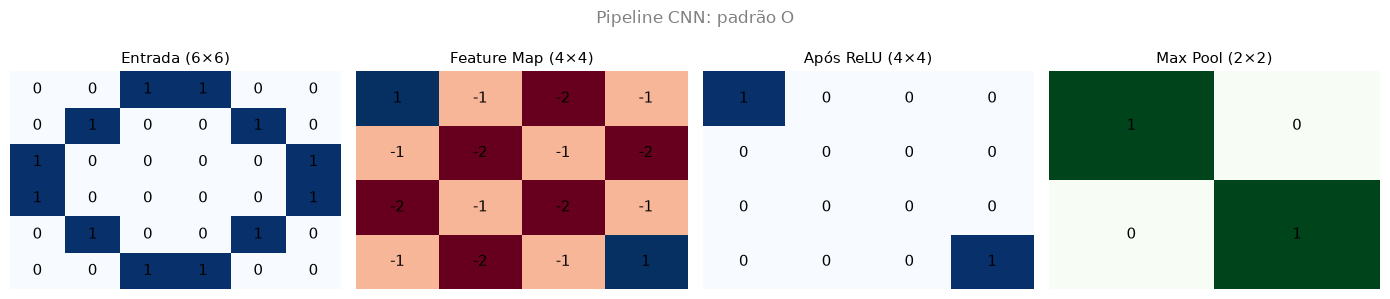

In [6]:
def forward(X, W_conv, b_conv, W_dense, b_dense):
    Z_conv = conv2d(X, W_conv, b_conv)          # (4, 4)
    A_conv = relu(Z_conv)                        # (4, 4)
    M      = maxpool(A_conv)                     # (2, 2)
    flat   = M.flatten()                         # (4,)
    probs  = softmax(W_dense @ flat + b_dense)   # (2,)
    cache  = (X, Z_conv, A_conv, M, flat)
    return probs, cache


# Teste com pesos iniciais
W_conv0  = np.array([[0, 0, 1], [0, 1, 0], [1, 0, 0]], dtype=float)
b_conv0  = -2.0
W_dense0 = np.array([[-0.80, -0.07, -0.20, -0.17],
                     [ 0.30,  0.50, -0.10,  0.40]], dtype=float)
b_dense0 = np.array([0.97, 0.10])

probs_O, _ = forward(O_base, W_conv0, b_conv0, W_dense0, b_dense0)
probs_X, _ = forward(X_base, W_conv0, b_conv0, W_dense0, b_dense0)

print(f'Padrão O: P(O)={probs_O[0]:.3f}  P(X)={probs_O[1]:.3f}')
print(f'Padrão X: P(O)={probs_X[0]:.3f}  P(X)={probs_X[1]:.3f}')

# Pipeline visual
_, (_, Z_o, A_o, M_o, _) = forward(O_base, W_conv0, b_conv0, W_dense0, b_dense0)

fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, mat, titulo, cmap in [
    (axes[0], O_base, 'Entrada (6×6)',    'Blues'),
    (axes[1], Z_o,    'Feature Map (4×4)', 'RdBu'),
    (axes[2], A_o,    'Após ReLU (4×4)',  'Blues'),
    (axes[3], M_o,    'Max Pool (2×2)',   'Greens'),
]:
    ax.imshow(mat, cmap=cmap, aspect='auto')
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            ax.text(j, i, f'{mat[i,j]:.0f}', ha='center', va='center', fontsize=11)
    ax.set_title(titulo, fontsize=11)
    ax.axis('off')
plt.suptitle('Pipeline CNN: padrão O', fontsize=12, color='gray')
plt.tight_layout()
plt.show()

## 6. Backward: como a rede se corrige

A lógica é a mesma do notebook 00: descobrir, para cada parâmetro, se a perda sobe ou desce quando ele aumenta, e então andar no sentido contrário. A diferença é que agora essa informação precisa atravessar as quatro operações, de trás para frente.

Antes disso, uma peça nova. No notebook 00 medimos o erro com o MSE, adequado para prever números. Para classificação usamos a **entropia cruzada** (*cross-entropy*):

$$\mathcal{L} = -\log\big(P(\text{classe correta})\big)$$

Ela olha **apenas a probabilidade que a rede deu para a resposta certa** e pune conforme essa probabilidade é baixa:

| Probabilidade dada à resposta certa | Perda |
|---|---|
| 0,99 (confiante e certo) | 0,01 |
| 0,50 (em dúvida) | 0,69 |
| 0,01 (confiante e errado) | 4,61 |

Ou seja: errar com confiança é o pior cenário possível, e é exatamente isso que o treinamento vai evitar.

### O caminho de volta, etapa por etapa

**Saída (softmax junto com entropia cruzada).** Existe um resultado de cálculo que simplifica tudo aqui:

$$\frac{\partial \mathcal{L}}{\partial \mathbf{z}} = \mathbf{p} - \mathbf{y}$$

onde $\mathbf{p}$ são as probabilidades previstas e $\mathbf{y}$ é a resposta certa escrita como `[1, 0]` para O ou `[0, 1]` para X. Esse jeito de escrever a resposta se chama **one-hot**, ou seja, "só uma posição acesa". Traduzindo a fórmula: *o erro na saída é simplesmente a diferença entre o que a rede achou e o que era certo*. Se ela disse `[0.7, 0.3]` e a resposta certa era O, o erro é `[-0.3, +0.3]`.

**Camada densa.**

$$\frac{\partial \mathcal{L}}{\partial W} = \mathbf{dz} \otimes \mathbf{x}^T \qquad\qquad \frac{\partial \mathcal{L}}{\partial \mathbf{x}} = W^T \mathbf{dz}$$

A primeira fórmula corrige os pesos da própria camada densa. A segunda repassa o erro para a camada anterior, e é ela que mantém a corrente andando.

**ReLU.** Deixa a correção passar somente onde a entrada era positiva.

**Max pooling.** Manda a correção apenas para a posição que foi a máxima de cada bloco.

**Convolução.**

$$\frac{\partial \mathcal{L}}{\partial W_{\text{conv}}} = \sum_{i,j} \frac{\partial \mathcal{L}}{\partial Z_{ij}} \cdot X_{i:i+F,\; j:j+F}$$

Aqui os 9 pesos do filtro finalmente são corrigidos. Como o mesmo filtro passou por todas as posições da imagem, a correção dele é a **soma** das contribuições de cada posição.

In [7]:
def backward(probs, y_label, cache, W_conv, W_dense):
    X, Z_conv, A_conv, M, flat = cache

    y    = np.zeros(2); y[y_label] = 1.0
    dz_d = probs - y                                        # gradiente saída

    dW_dense = np.outer(dz_d, flat)                         # gradiente Dense
    db_dense = dz_d.copy()
    d_flat   = W_dense.T @ dz_d

    dA_conv  = grad_maxpool(d_flat.reshape(M.shape), A_conv)  # gradiente MaxPool
    dZ_conv  = grad_relu(dA_conv, Z_conv)                     # gradiente ReLU
    dW_conv, db_conv = grad_conv2d(dZ_conv, X, W_conv)        # gradiente Conv

    return dW_conv, db_conv, dW_dense, db_dense


def cross_entropy(probs, y_label):
    return -np.log(probs[y_label] + 1e-9)


def predict(X, W_conv, b_conv, W_dense, b_dense):
    probs, _ = forward(X, W_conv, b_conv, W_dense, b_dense)
    return np.argmax(probs)


print('backward, cross_entropy e predict definidos.')

backward, cross_entropy e predict definidos.


## 7. Treinamento

O loop é o mesmo do notebook 00, com uma diferença: em vez de usar todos os exemplos de uma vez para calcular cada ajuste, vamos atualizar os pesos **um exemplo por vez**, em ordem sorteada. Essa variação se chama **SGD** (*Stochastic Gradient Descent*, gradiente descendente estocástico), e "estocástico" aqui significa apenas isso, que a ordem é sorteada.

```
para cada época:
    para cada exemplo (imagem, rótulo), em ordem sorteada:
        1. forward   ->  probabilidades
        2. loss      ->  entropia cruzada
        3. backward  ->  derivadas
        4. update    ->  peso = peso - η · derivada
```

### De onde vêm os dados

Temos só dois desenhos, o O e o X. Dois exemplos não treinam nada, e além disso queremos uma rede capaz de reconhecer desenhos **imperfeitos**, não apenas as duas figuras originais.

A solução é criar muitas variações somando **ruído aleatório** a cada pixel, como fizemos na seção 9 do notebook 00. Cada cópia fica um pouco borrada, um pouco diferente, e é justamente isso que obriga a rede a aprender a **forma** em vez de decorar dois desenhos específicos.

Treino: 4000 amostras | Teste: 2000 amostras


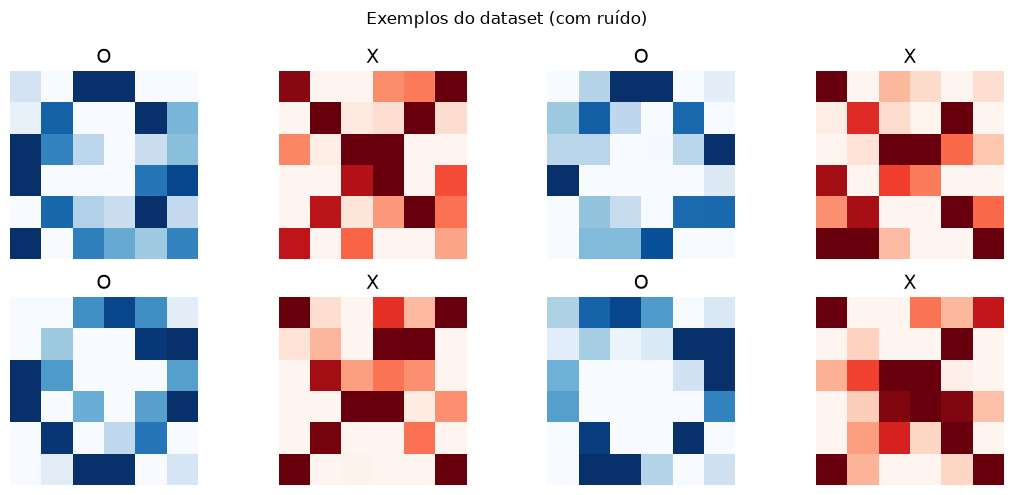

In [8]:
# Geração de dados com ruído gaussiano
def gerar_dataset(n=100, ruido=0.6, seed=42):
    rng = np.random.default_rng(seed)
    X_data, y_data = [], []
    for _ in range(n):
        X_data.append(np.clip(O_base + rng.normal(0, ruido, O_base.shape), 0, 1))
        y_data.append(0)
        X_data.append(np.clip(X_base + rng.normal(0, ruido, X_base.shape), 0, 1))
        y_data.append(1)
    return np.array(X_data), np.array(y_data)


X_train, y_train = gerar_dataset(n=2000, seed=42)
X_test,  y_test  = gerar_dataset(n=1000, seed=99)

print(f'Treino: {X_train.shape[0]} amostras | Teste: {X_test.shape[0]} amostras')

# Visualizar alguns exemplos
fig, axes = plt.subplots(2, 4, figsize=(11, 5))
for k, ax in enumerate(axes.flat):
    ax.imshow(X_train[k], cmap='Blues' if y_train[k] == 0 else 'Reds', vmin=0, vmax=1)
    ax.set_title('O' if y_train[k] == 0 else 'X', fontsize=14)
    ax.axis('off')
plt.suptitle('Exemplos do dataset (com ruído)', fontsize=12)
plt.tight_layout()
plt.show()


### Pesos iniciais e hiperparâmetros

Os pesos começam com valores aleatórios pequenos, sorteados em torno de zero. Isso é importante: se todos começassem iguais, todos receberiam a mesma correção e nunca se diferenciariam, e a rede jamais aprenderia padrões distintos.

| Hiperparâmetro | Valor | Significado |
|---|---|---|
| `lr` (taxa de aprendizado) | 0,05 | tamanho do passo, exatamente como no notebook 00 |
| `epochs` | 30 | quantas vezes a rede verá o conjunto completo de treino |

O treino leva alguns segundos porque estamos fazendo todas as contas em Python puro, sem nenhuma otimização. É o preço de ver tudo funcionando por dentro. No notebook 02 o PyTorch fará o mesmo trabalho muito mais rápido.

In [9]:
# Inicialização dos pesos
rng = np.random.default_rng(0)
W_conv  = rng.normal(0, 0.1, (3, 3))
b_conv  = 0.0
W_dense = rng.normal(0, 0.1, (2, 4))
b_dense = np.zeros(2)

# Loop de treinamento (SGD)
lr     = 0.05
epochs = 30
historico = []

for ep in range(epochs):
    perda_total = 0.0
    for i in np.random.permutation(len(X_train)):
        probs, cache = forward(X_train[i], W_conv, b_conv, W_dense, b_dense)
        perda_total += cross_entropy(probs, y_train[i])

        dW_conv, db_conv, dW_dense, db_dense = backward(probs, y_train[i], cache, W_conv, W_dense)

        W_conv  -= lr * dW_conv
        b_conv  -= lr * db_conv
        W_dense -= lr * dW_dense
        b_dense -= lr * db_dense

    historico.append(perda_total / len(X_train))
    if (ep + 1) % 10 == 0:
        print(f'Época {ep+1:3d}/{epochs}  |  Loss: {historico[-1]:.4f}')

print('\nTreinamento concluído.')

Época  10/30  |  Loss: 0.0584
Época  20/30  |  Loss: 0.0579
Época  30/30  |  Loss: 0.0561

Treinamento concluído.


### O que observar nos resultados

Dois gráficos e um número:

- **curva de perda:** deve **cair** e depois estabilizar. Se subir ou ficar travada no mesmo valor, algo está errado, e o primeiro suspeito é sempre a taxa de aprendizado;
- **acurácia no teste:** a porcentagem de acertos em imagens que a rede **nunca viu durante o treino**. Esse é o número que importa de verdade, e é por isso que separamos um conjunto de teste: acertar aquilo que já se viu não prova nada;
- **exemplos individuais:** os títulos em verde são acertos, os em vermelho são erros.

Com 20 parâmetros, essa rede costuma passar de 98% de acerto.

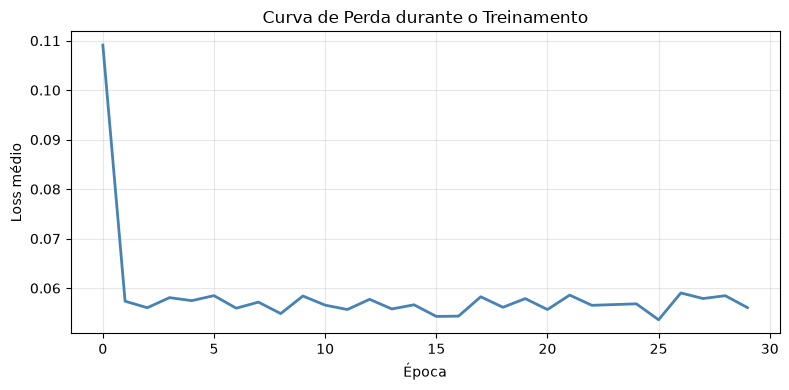

Acurácia no conjunto de teste: 98.5%


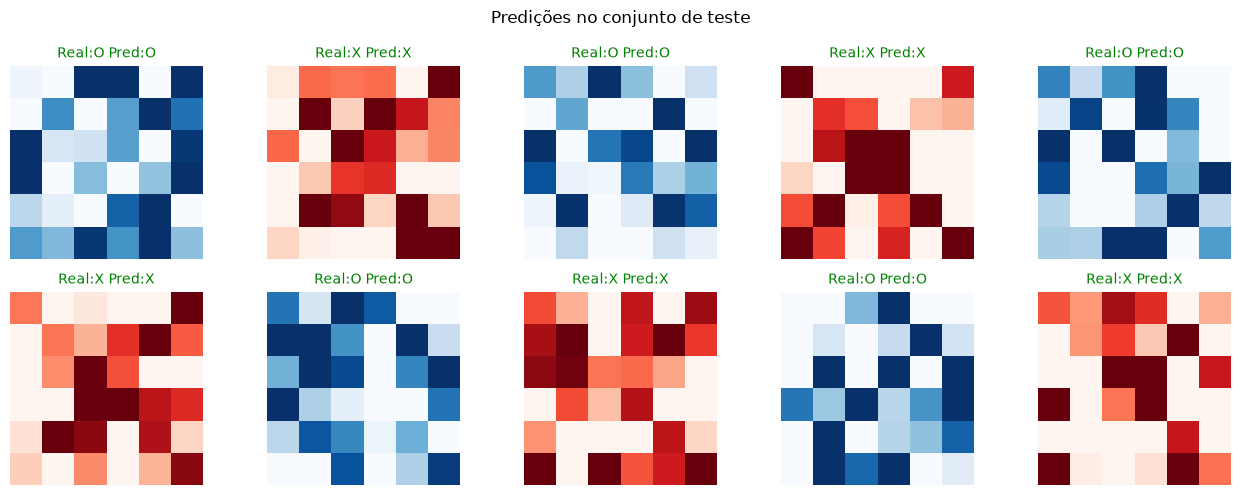

In [10]:
# Curva de perda
plt.figure(figsize=(8, 4))
plt.plot(historico, color='steelblue', linewidth=2)
plt.title('Curva de Perda durante o Treinamento')
plt.xlabel('Época'); plt.ylabel('Loss médio')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Acurácia no teste
preds    = np.array([predict(X_test[i], W_conv, b_conv, W_dense, b_dense) for i in range(len(X_test))])
acuracia = (preds == y_test).mean() * 100
print(f'Acurácia no conjunto de teste: {acuracia:.1f}%')

# Visualizar predições
fig, axes = plt.subplots(2, 5, figsize=(13, 5))
for k, ax in enumerate(axes.flat):
    real = 'O' if y_test[k] == 0 else 'X'
    pred = 'O' if preds[k] == 0 else 'X'
    ax.imshow(X_test[k], cmap='Blues' if y_test[k] == 0 else 'Reds', vmin=0, vmax=1)
    ax.set_title(f'Real:{real} Pred:{pred}', color='green' if real == pred else 'red', fontsize=10)
    ax.axis('off')
plt.suptitle('Predições no conjunto de teste', fontsize=12)
plt.tight_layout()
plt.show()


## 8. Conclusão

### O que construímos

| Componente | O que faz | Fórmula principal |
|---|---|---|
| **Convolução** | passa um filtro pequeno pela imagem procurando um padrão | $z_{ij} = \sum_{p,q} x_{i+p,j+q}\,w_{pq} + b$ |
| **ReLU** | zera os negativos, permitindo aprender padrões complexos | $A = \max(0, Z)$ |
| **Max pooling** | resume cada bloco pelo seu maior valor | $M_{ij} = \max(\text{bloco})$ |
| **Softmax** | transforma números soltos em probabilidades | $p_k = e^{z_k} / \sum_j e^{z_j}$ |
| **Densa** | combina os padrões encontrados e decide a classe | $\mathbf{z} = W\mathbf{x} + b$ |
| **Entropia cruzada** | mede o erro de uma classificação | $\mathcal{L} = -\log P(\text{correta})$ |
| **Backpropagation** | leva a correção de volta por todas as camadas | regra da cadeia |

### As três ideias que fazem a CNN funcionar

1. **Pesos compartilhados:** um único filtro percorre a imagem inteira. Poucos parâmetros, e o padrão é reconhecido em qualquer posição.
2. **Vizinhança local:** cada conta olha apenas um quadradinho, o que preserva a informação de que pixels próximos formam desenhos juntos.
3. **Hierarquia:** empilhando camadas, os padrões simples da primeira (riscos, bordas) se combinam em padrões complexos nas seguintes (olhos, rodas, letras).

### Para praticar

1. Troque os números do `W_demo` na seção 3, por exemplo colocando os 1 na outra diagonal, e veja o mapa de características mudar.
2. Aumente o `ruido` de `0.6` para `1.2` na geração do dataset. A acurácia cai? Quanto?
3. Coloque a taxa de aprendizado em `0.5` e treine de novo. Observe o que acontece com a curva de perda.

---

**Próximo passo:** no notebook `02_cnn_pytorch.ipynb` passamos a usar o **PyTorch**, que escreve o forward e o backward por nós, e partimos para imagens de 28×28 com 10 classes em vez de 2.